# Walkthrough: `03_leakage_audit.py` (Preventing Future-Information Leakage)

### Simple Summary
**This script inspects all 78 columns across our origination table and monthly loan history and stamps each field with a strict time-travel rule—ensuring that no outcome, exit, or loss column (`quarantined`) ever sneaks into a risk model, and that monthly features only use month `t-1` information.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook opens the fixed `0.03%` sample (`mortgages_sample.duckdb`) strictly **read-only in memory** and runs every leakage check without writing to disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Inspect Schema</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">DESCRIBE 78 live columns</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. Stamp 4 Classes</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">origination, lag-1, quar, key</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. 2 Guardrail Checks</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">Zero gaps &amp; zero leaks</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. Class Breakdown</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Usable vs. blocked chart</text>
</svg>
</div>

---
### 1. Importing Leakage Rules & Inspecting Live Database Columns
In credit risk modeling, using future information (such as `zero_balance_code` or `foreclosure_costs` from the exit month) makes a PD model look artificially accurate in testing and fail in production. We load the classification rules from `03_leakage_audit.py` and attach the fixed `0.03%` sample DB read-only to verify every live column.

In [1]:
# Load system, database, dataframe, and plotting libraries
# Import importlib, pathlib, duckdb, pandas, and matplotlib for read-only leakage verification
import importlib
import sys
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# Locate residential_mortgage/ root and register 00_data and 01_data_foundation script paths
# Walk upward until reaching residential_mortgage/, then add scripts/ folders to sys.path
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

for p in (PACKAGE_ROOT / "00_data/scripts", PACKAGE_ROOT / "01_data_foundation/scripts"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

# Import the leakage audit module and attach the fixed 0.03% sample DB in memory
# Load 03_leakage_audit and open mortgages_sample.duckdb strictly as READ_ONLY
la = importlib.import_module("03_leakage_audit")
FIXED_SAMPLE_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/00_data/mortgages_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_SAMPLE_DB.as_posix()}' AS src (READ_ONLY)")

# Fetch the live column lists from both loans_table and loan_monthly_view
# Query DESCRIBE on both attached objects to verify exact column counts
in_db = [(la.LOANS, r[0]) for r in con.execute("DESCRIBE src.loans_table").fetchall()] + [
    (la.MONTHLY, r[0]) for r in con.execute("DESCRIBE src.loan_monthly_view").fetchall()
]
pd.DataFrame([{
    "loans_table Columns": sum(1 for s, _ in in_db if s == la.LOANS),
    "loan_monthly_view Columns": sum(1 for s, _ in in_db if s == la.MONTHLY),
    "Total Columns to Classify": len(in_db),
    "Ruleset Entries": len(la.CLASSIFICATION),
}])

,loans_table Columns,loan_monthly_view Columns,Total Columns to Classify,Ruleset Entries
0,35,43,78,78


There are **78 live columns** across both objects (`35` in `loans_table` and `43` in `loan_monthly_view`), matching the **78 entries** in `CLASSIFICATION`. Next, we verify that every single column is classified once and inspect examples of each class.

---
### 2. Checking Completeness & Reviewing the Four Time-Travel Classes
Every column falls into one of four classes:
* **`origination`:** Known when the loan is made (e.g., `orig_ltv`, `credit_score`). Usable in any month.
* **`monthly_lag_1`:** Observed during servicing (e.g., `delinquency_status`, `current_upb`). Must be lagged to month `t-1` when predicting month `t`.
* **`quarantined`:** Exit, outcome, or loss amounts (e.g., `zero_balance_code`, `net_sales_proceeds`). Never usable as predictors.
* **`key`:** Identifiers (`loan_id`, `reporting_period`). Used only for joining and sorting.

In [2]:
# Run compare_to_database to ensure zero unclassified, duplicated, or missing columns
# Cross-check listed (source, field) pairs against the live database pairs
listed = [(s, n) for s, n, _, _ in la.CLASSIFICATION]
unclassified, duplicated, missing = la.compare_to_database(listed, in_db)
print(f"Unclassified: {len(unclassified)}, Duplicated: {len(duplicated)}, Missing: {len(missing)}")

# Build the complete leakage table in memory using restated counts from the sample DB
# Query origination_restatements_table via src prefix and assemble rows via build_rows()
restated = {r[0]: int(r[1]) for r in con.execute("SELECT column_name, SUM(loans_restated) FROM src.origination_restatements_table GROUP BY column_name").fetchall()}
rows = la.build_rows(restated)
leak_df = pd.DataFrame(rows, columns=[
    "field_name", "source_object", "layout_position", "layout_name",
    "field_class", "lag_rule", "usable_as_feature", "loans_restated", "reason"
])

# Display one representative example from each of the 4 leakage classes
# Group by field_class and take the first entry to illustrate lag_rule and usable_as_feature
leak_df.groupby("field_class", sort=False).first().reset_index()[["field_class", "source_object", "field_name", "lag_rule", "usable_as_feature", "reason"]]

Unclassified: 0, Duplicated: 0, Missing: 0


,field_class,source_object,field_name,lag_rule,usable_as_feature,reason
0,key,loans_table,loan_id,join only,False,Loan identifier. Joins the tables; not a feature.
1,origination,loans_table,channel,none,True,"How the loan was sold to Fannie Mae (retail, b..."
2,monthly_lag_1,loan_monthly_view,servicer_name,t-1,True,Servicer at the reporting date. A change of se...
3,quarantined,loan_monthly_view,zero_balance_code,never,False,Why the loan left the pool. Outcome; filled on...


Every single column matches cleanly (**0 unclassified, 0 duplicated, 0 missing**). Notice how `usable_as_feature` flips to `False` for `quarantined` and `key` fields. Next, we run the hard guardrail check and visualize how many columns fall into each class.

---
### 3. Verifying the Zero-Leak Guardrail & Visualizing Field Permissions
Before committing `field_leakage_table` in production, `03_leakage_audit.py` enforces a second check: **no `quarantined` field may ever be marked usable or carry a lag other than `never`**. We verify both checks in memory and plot the 78-column breakdown.

,Check,Status
0,Every column classified exactly once (78/78),PASS
1,No quarantined field is marked usable,PASS


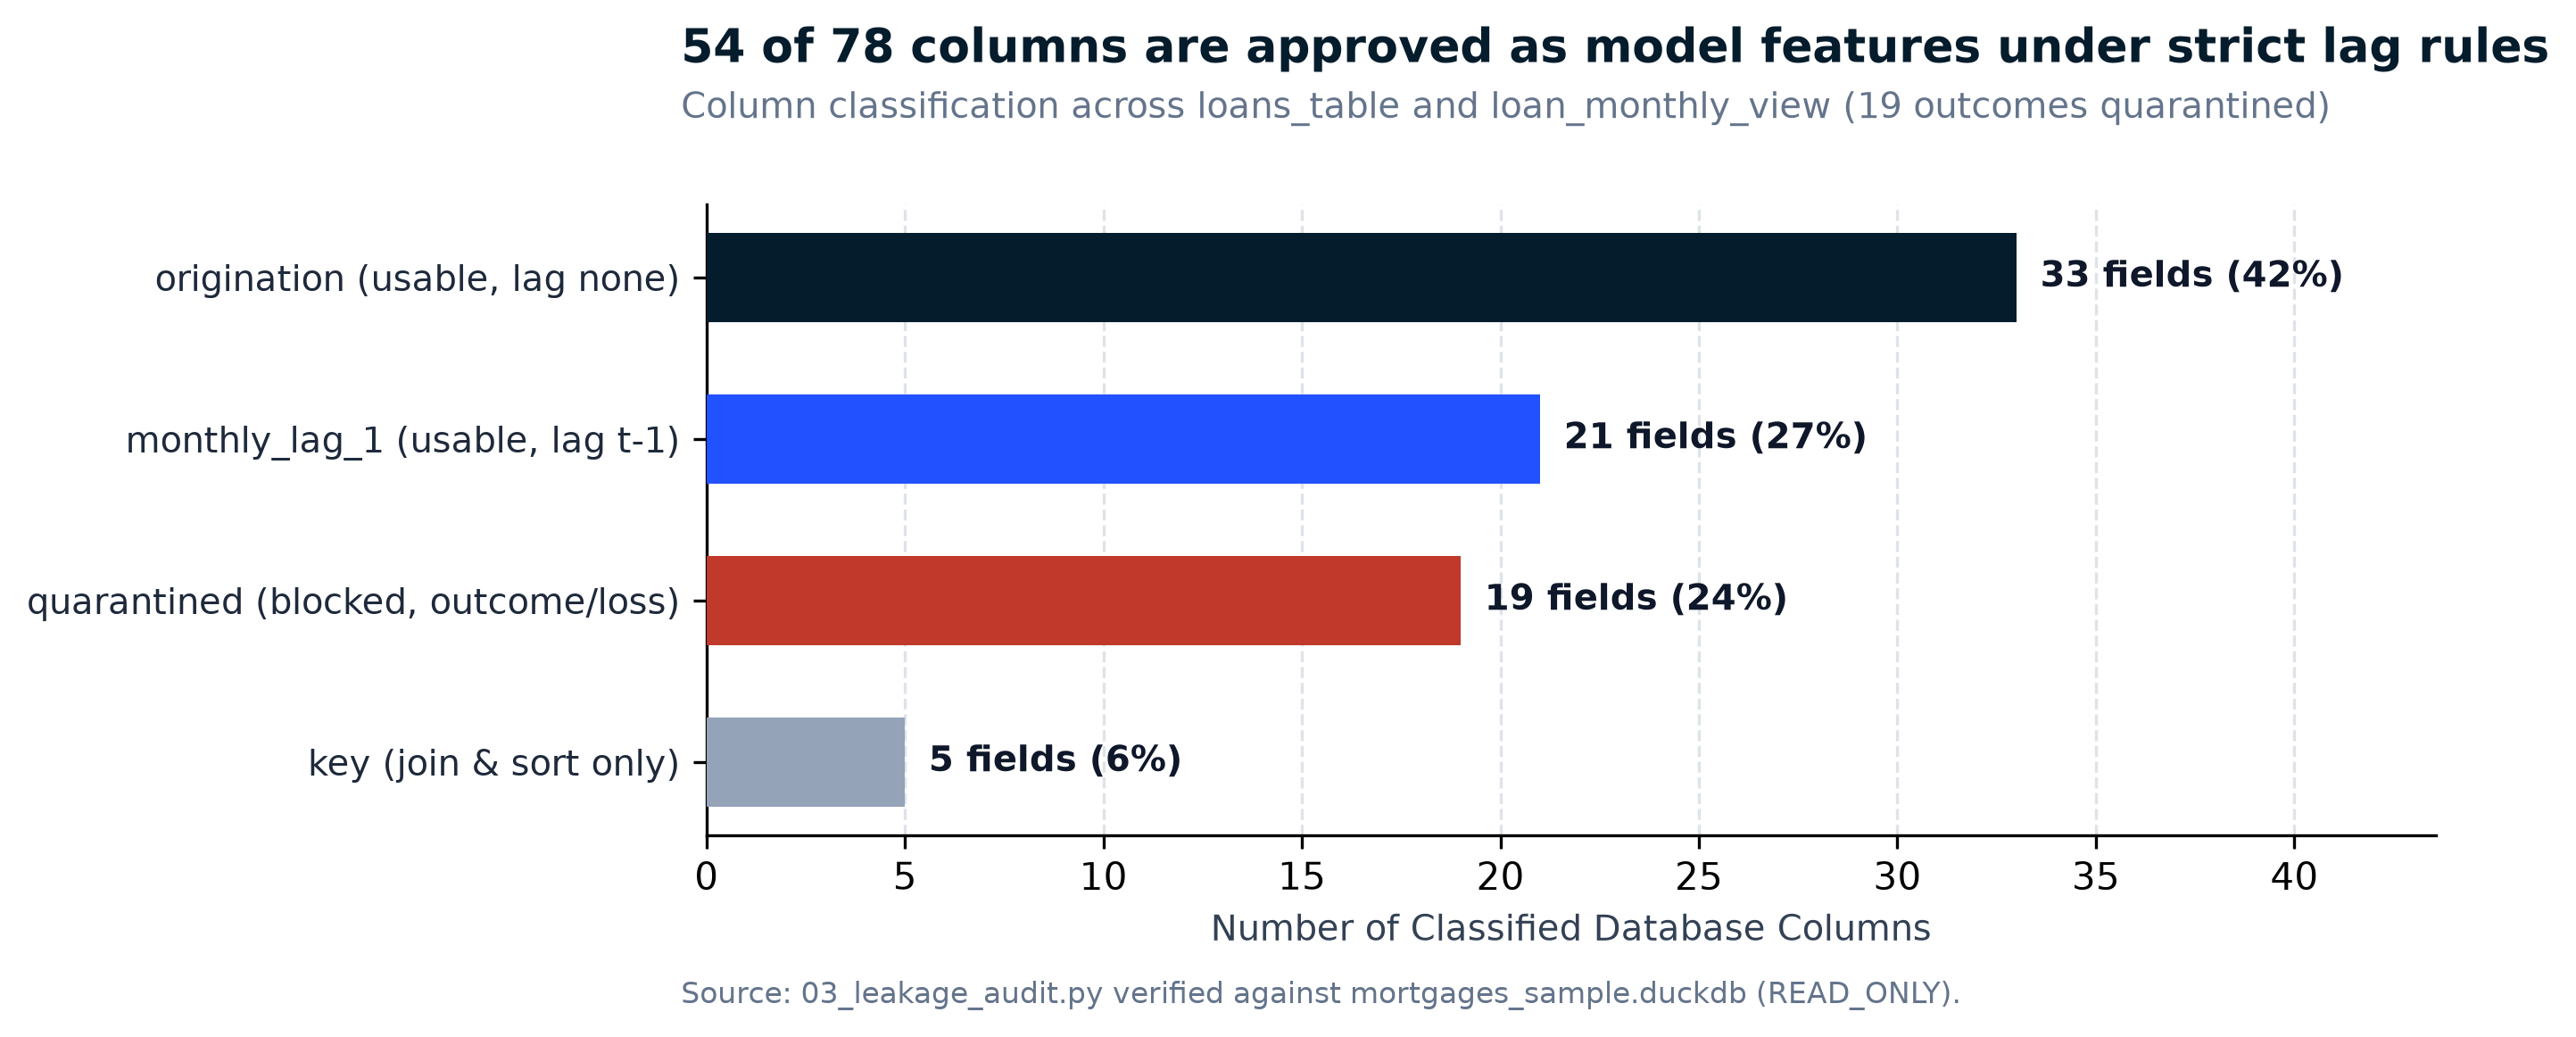

In [3]:
# Evaluate both leakage-audit guardrails on the in-memory classification DataFrame
# Check complete column coverage and confirm zero quarantined fields are marked usable
check1 = not (unclassified or duplicated or missing)
bad_quar = int(((leak_df["field_class"] == "quarantined") & (leak_df["usable_as_feature"] | (leak_df["lag_rule"] != "never"))).sum())
check2 = bad_quar == 0
display(pd.DataFrame([
    {"Check": "Every column classified exactly once (78/78)", "Status": "PASS" if check1 else "FAIL"},
    {"Check": "No quarantined field is marked usable", "Status": "PASS" if check2 else "FAIL"},
]))

# Plot a McKinsey-style horizontal bar chart of field counts across the 4 leakage classes
# Count columns per field_class, color usable classes blue/navy and blocked classes red/slate, and label directly
order = ["origination", "monthly_lag_1", "quarantined", "key"]
cls_counts = [int((leak_df["field_class"] == c).sum()) for c in order]
cls_labels = ["origination (usable, lag none)", "monthly_lag_1 (usable, lag t-1)", "quarantined (blocked, outcome/loss)", "key (join & sort only)"]
cls_colors = ["#051C2C", "#2251FF", "#C0392B", "#94A3B8"]

fig, ax = plt.subplots(figsize=(9.5, 3.8), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
ax.barh(range(len(order)), cls_counts, color=cls_colors, height=0.55, zorder=3)
for i, cnt in enumerate(cls_counts):
    ax.text(cnt + 0.6, i, f"{cnt} fields ({100*cnt/len(leak_df):.0f}%)", va="center", fontsize=9.5, fontweight="bold", color="#0F172A")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(cls_labels, fontsize=9.5, color="#1E293B")
ax.invert_yaxis()
ax.set_xlim(0, max(cls_counts) * 1.32)
ax.grid(axis="x", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Number of Classified Database Columns", fontsize=9.5, color="#334155")
fig.text(0.27, 0.94, "54 of 78 columns are approved as model features under strict lag rules", fontsize=12.5, fontweight="bold", color="#051C2C")
fig.text(0.27, 0.885, "Column classification across loans_table and loan_monthly_view (19 outcomes quarantined)", fontsize=9.5, color="#64748B")
fig.text(0.27, 0.015, "Source: 03_leakage_audit.py verified against mortgages_sample.duckdb (READ_ONLY).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.28, right=0.96, top=0.80, bottom=0.18)
plt.show()

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()

All **2/2 checks pass**: **54 fields** are approved (`33` origination + `21` lagged monthly), while **19 outcome/loss columns** are strictly quarantined and **5 keys** remain join-only. Next, `04_feature_catalogue.py` measures live fill rates for all 78 fields on the `0.03%` sample.